# SiN Grating Coupler -- Waveguide, Overlap and Mesh Validation (Step 1)

This notebook validates the 2D x-z Meep model that the next two notebooks optimize: a
grating coupler etched into a **400 nm SiN core** (n = 2.0) on a 2 µm BOX over a Si
substrate, with oxide top cladding, coupling TE light at **1.35 µm** to an **SMF-28**
fiber (MFD 9.2 µm) tilted 10°.

The question behind the project is whether a **meta-grating** (three tooth/groove
pairs, "meta-atoms", per period) can beat a **conventional grating** (one pair per
period) once both are optimized the same way. Before any optimization can be trusted,
the simulation itself has to be shown to be right and converged. This notebook checks,
in order:

1. the SiN slab mode (n_eff and polarization) against an exact transfer-matrix solution;
2. guided propagation, power normalization and the phase convention in a straight guide;
3. the coupling-efficiency (overlap) definition on synthetic fields;
4. that the results do not depend on the simulation domain (PML, margins, monitors, run time);
5. mesh convergence for a conventional and a meta-atom grating, in both geometry
   representations used later (Meep `Block`s and a differentiable `MaterialGrid`);
6. the design period from the measured Bloch index;
7. the effect of the BOX thickness;
8. that η changes smoothly with a width at the candidate resolutions (gradient-based
   optimization needs this);
9. that the adjoint gradient matches finite differences;
10. a literature benchmark (a published single-etch SiN coupler).

**Model:** 2D x-z cross-section with real bulk indices (SiN 2.0, SiO₂ 1.44, Si 3.45),
non-dispersive, y-invariant (no lateral taper or finite aperture). Physical TE (E along
y) is Meep's `mp.TM` parity in this rotated-axis convention. Code:
`src/pic_toolkit/meep_sim/sin_grating.py`.

**Do not use "Run All."** The full notebook takes several hours of single-core FDTD.
Every expensive section caches its result in `meta/data/step1/`, so a re-run (or a resumed
run after an interruption) reloads instead of recomputing.

## 0. Setup

In [1]:
# Imports, plotting style, cache folder, and the two reference designs used throughout.
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pic_toolkit.meep_sim import sin_grating as sg
from pic_toolkit import style

style.apply_style()
CACHE = Path.cwd().parent / "data" / "step1"
K0 = 2 * np.pi / sg.DEFAULT_PARAMS["wl0_um"]

# Reference designs at a provisional period of 0.90 um (Section 6 derives the design period):
#   conventional: one 450 nm tooth + 450 nm groove per period, 200 nm etch;
#   meta seed:    three atoms with every width >= 100 nm (the minimum feature), 200 nm etch.
REF = {"period_um": 0.90, "n_atoms": 1, "widths_um": [0.45, 0.45], "etch_um": 0.20}
META = {"period_um": 0.90, "n_atoms": 3, "widths_um": [0.25, 0.12, 0.15, 0.10, 0.13, 0.15], "etch_um": 0.20}
RES_LIST = [20, 30, 40, 60, 80, 100, 120, 160]


def summarize(r, x0=None):
    # eta at 1.35 um with the fiber at its best position (or at x0), and the power budget.
    i0 = int(np.argmin(np.abs(r["wl"] - r["params"]["wl0_um"])))
    if x0 is None:
        x0, eta = sg.best_x0(r)
    else:
        eta = sg.eta_overlap(r["x_up"], r["ez_up"][i0], r["hx_up"][i0], r["wl"][i0], r["p_in"][i0], r["params"], x0)
    spec = sg.eta_spectrum(r, x0)
    k = int(np.argmax(spec))
    if 0 < k < len(spec) - 1:   # parabolic refinement of the peak wavelength
        a, b, c = spec[k - 1], spec[k], spec[k + 1]
        wl_peak = r["wl"][k] + 0.5 * (a - c) / (a - 2 * b + c) * (r["wl"][k + 1] - r["wl"][k - 1]) / 2
    else:
        wl_peak = r["wl"][k]
    return {"eta": eta, "x0": x0, "wl_peak": float(wl_peak), "up": float(r["up"][i0]), "down": float(r["down"][i0]),
            "R": float(r["R"][i0]), "T": float(r["T"][i0]),
            "budget": float(r["up"][i0] + r["down"][i0] + r["R"][i0] + r["T"][i0]), "wall_s": r["wall_s"]}


print("defaults:", {k: sg.DEFAULT_PARAMS[k] for k in ("core_um", "box_um", "top_um", "n_core", "n_box", "wl0_um",
                                                   "fiber_angle_deg", "mfd_um", "n_periods", "z_mon_up_offset_um")})

defaults: {'core_um': 0.4, 'box_um': 2.0, 'top_um': 2.5, 'n_core': 2.0, 'n_box': 1.44, 'wl0_um': 1.35, 'fiber_angle_deg': 10.0, 'mfd_um': 9.2, 'n_periods': 22, 'z_mon_up_offset_um': 1.0}


## 1. SiN slab mode

The guided mode is the input to everything else, so its effective index and its
polarization are checked first.

- **Exact reference:** the transfer-matrix (TMM) solution for the TE mode of a 400 nm,
  n = 2.0 slab in n = 1.44 oxide at 1.35 µm.
- **On the FDTD grid:** Meep's eigensolver at the source plane, for both parities. Physical
  TE (E along y) is `mp.TM` here and must be the higher-index mode, with only an `Ez`
  component. Physical TM (`mp.TE`) is solved for contrast.

The eigensolver span is the source's own span (core ± 1 µm). A span that reaches the
Si substrate returns the substrate's slab mode (n_eff ≈ 3.39) instead of the core mode.

res  20: physical TE n_eff 1.76292 (-0.883% vs TMM), physical TM 1.68347


res  40: physical TE n_eff 1.77177 (-0.385% vs TMM), physical TM 1.68444


res  80: physical TE n_eff 1.77546 (-0.178% vs TMM), physical TM 1.68483


res 160: physical TE n_eff 1.77711 (-0.085% vs TMM), physical TM 1.68500
TMM (exact) TE: unetched 1.77862, 200 nm etched 1.61270


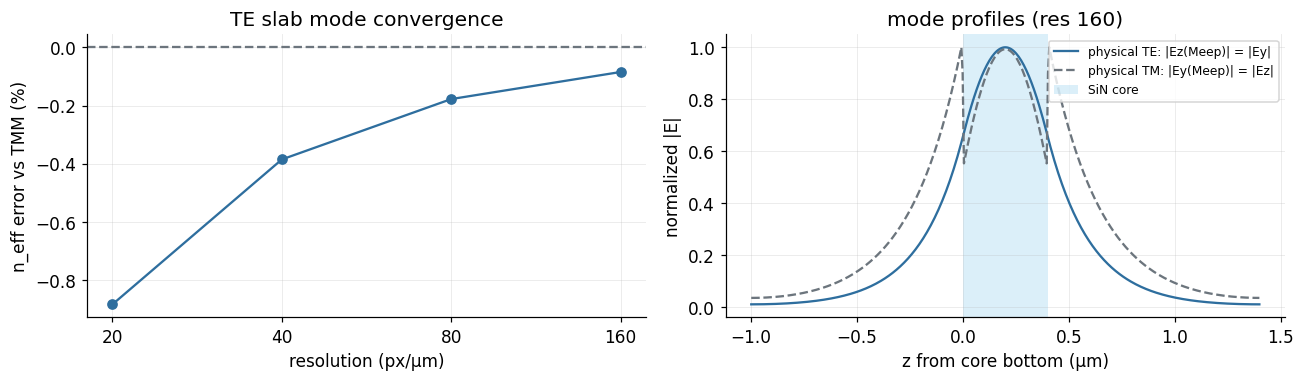

In [2]:
# TE n_eff: exact TMM vs Meep's eigensolver on the FDTD grid, at increasing resolution.
N_TMM = sg.te_slab_neff([(2.0, 0.40)], 1.44, 1.44, 1.35)
N_TMM_ETCHED = sg.te_slab_neff([(2.0, 0.20)], 1.44, 1.44, 1.35)   # 200 nm left under a 200 nm etch
rows = []
for r in (20, 40, 80, 160):
    n_te, zs, f_te = sg.meep_slab_neff({"resolution": r}, parity=sg.mp.TM)
    n_tm, _, f_tm = sg.meep_slab_neff({"resolution": r}, parity=sg.mp.TE)
    rows.append((r, n_te, n_tm))
    print(f"res {r:>3}: physical TE n_eff {n_te:.5f} ({100 * (n_te / N_TMM - 1):+.3f}% vs TMM), physical TM {n_tm:.5f}")
print(f"TMM (exact) TE: unetched {N_TMM:.5f}, 200 nm etched {N_TMM_ETCHED:.5f}")

assert all(n_te > n_tm for _, n_te, n_tm in rows), "physical TE must be the higher-index mode"
assert abs(rows[-1][1] / N_TMM - 1) < 0.002, "res-160 eigensolve should match TMM within 0.2%"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot([r for r, _, _ in rows], [100 * (n / N_TMM - 1) for _, n, _ in rows], "o-", color=style.COLOR_STEEL)
axes[0].axhline(0, color=style.COLOR_REFERENCE, ls="--")
axes[0].set(xscale="log", xlabel="resolution (px/µm)", ylabel="n_eff error vs TMM (%)", title="TE slab mode convergence")
axes[0].set_xticks([20, 40, 80, 160], ["20", "40", "80", "160"])
axes[0].minorticks_off()
d = sg.domain(sg.resolve(None))
axes[1].plot(zs - d["z_box1"], f_te[0] / f_te[0].max(), color=style.COLOR_STEEL, label="physical TE: |Ez(Meep)| = |Ey|")
axes[1].plot(zs - d["z_box1"], f_tm[1] / f_tm[1].max(), color=style.COLOR_REFERENCE, ls="--", label="physical TM: |Ey(Meep)| = |Ez|")
axes[1].axvspan(0, 0.4, color=style.COLOR_CYAN, alpha=0.3, lw=0, label="SiN core")
axes[1].set(xlabel="z from core bottom (µm)", ylabel="normalized |E|", title="mode profiles (res 160)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Straight waveguide: propagation, power normalization and phase convention

With no grating, the launched mode must travel to the far end unchanged. This checks:

- **transmission ≈ 1, reflection ≈ 0, no radiation** (up/down ≈ 0);
- **power normalization:** the incident mode power |α₊|² used to normalize every result
  equals the flux through a vertical plane after the guide;
- **phase convention:** the phase of the DFT field along the core grows with x
  (exp(+ikx)), so a forward-tilted fiber beam is written with exp(+i k sinθ x)
  (`sg.PHASE_SIGN = +1`). The phase slope also gives n_eff independently of the eigensolver.

In [3]:
# Straight guide at two resolutions (cached).
def straight(res):
    r = sg.run_forward({"resolution": res, "n_periods": 0, "tail_um": 12.0}, waveguide_probes=True)
    i0 = int(np.argmin(np.abs(r["wl"] - 1.35)))
    x, ez = r["x_core"], r["ez_core"][i0]
    sel = (x > r["dom"]["x_src"] + 1.0) & (x < r["dom"]["x_right"] - 1.0)
    slope = np.polyfit(x[sel], np.unwrap(np.angle(ez[sel])), 1)[0]
    return {"res": res, "T": float(r["T"][i0]), "R": float(r["R"][i0]), "up": float(r["up"][i0]),
            "down": float(r["down"][i0]), "flux_vert": float(r["flux_vert"][i0]), "a_trans": float(r["a_trans"][i0]),
            "n_eff_phase": float(slope / K0)}


wg = sg.cached(CACHE / "straight.pkl", lambda: [straight(40), straight(80)])
for s in wg:
    print(f"res {s['res']}: T {s['T']:.4f}, R {s['R']:.1e}, up {s['up']:.1e}, down {s['down']:.1e}, "
          f"flux through a vertical plane / |a+|^2 = {s['flux_vert']:.4f}, n_eff from phase slope {s['n_eff_phase']:+.5f} "
          f"(TMM {N_TMM:.5f})")
for s in wg:
    assert abs(s["T"] - 1) < 0.01 and s["R"] < 1e-3, "straight guide must transmit everything"
    assert abs(s["flux_vert"] - 1) < 0.01, "|alpha+|^2 must equal the transmitted flux"
    assert s["n_eff_phase"] > 0, "forward-wave DFT phase must grow with x (PHASE_SIGN = +1)"
    assert abs(s["n_eff_phase"] / N_TMM - 1) < 0.01, "phase-slope n_eff must match TMM within 1%"

res 40: T 0.9998, R 1.0e-05, up 1.7e-05, down 4.9e-06, flux through a vertical plane / |a+|^2 = 0.9998, n_eff from phase slope +1.77661 (TMM 1.77862)
res 80: T 0.9997, R 7.9e-07, up 1.5e-05, down 4.7e-06, flux through a vertical plane / |a+|^2 = 0.9998, n_eff from phase slope +1.77697 (TMM 1.77862)


## 3. Coupling-efficiency definition

η = |X|² / (4 P_fib P_in), with X = ∫(E_y,sim H*_x,fib + E*_y,fib H_x,sim) dx on a line
1.0 µm above the SiN, P_in the incident mode power and P_fib the fiber beam's power
through the line. Two synthetic checks with known answers:

- **self-overlap:** a field equal to the fiber mode, normalized to unit input power, gives η = 1;
- **offset:** the fiber beam's footprint on the line is a Gaussian of 1/e half-width
  w₀/cos θ, so two identical beams offset by Δ along the line overlap in power as
  η = exp(−(Δ cos θ)² / w₀²) (the standard result for offset Gaussian beams).

Section 5 also compares the up-going power computed from the same DFT fields with
Meep's own flux monitor.

In [4]:
# Synthetic overlap checks on a fine line.
p = sg.resolve(None)
x = np.arange(-20, 40, 0.01)
ey, hx = sg.fiber_mode(x, 10.0, 1.35, p)
p_f = abs(np.real(np.sum(ey * np.conj(hx))) * 0.01)
self_eta = sg.eta_overlap(x, -ey, hx, 1.35, p_f, p, 10.0)
print(f"self-overlap: {self_eta:.6f}")
th, w0 = math.radians(p["fiber_angle_deg"]), p["mfd_um"] / 2
for delta in (1.0, 2.0, 4.0):
    num = sg.eta_overlap(x, -ey, hx, 1.35, p_f, p, 10.0 + delta)
    ana = math.exp(-((delta * math.cos(th)) ** 2) / w0**2)
    print(f"offset {delta} um: numeric {num:.5f}, analytic {ana:.5f}")
    assert abs(num - ana) < 1e-3
assert abs(self_eta - 1) < 1e-6

self-overlap: 1.000000
offset 1.0 um: numeric 0.95520, analytic 0.95520
offset 2.0 um: numeric 0.83249, analytic 0.83249
offset 4.0 um: numeric 0.48030, analytic 0.48030


> **STOP -- the mode, the normalization and the overlap must all pass before the
> grating runs below mean anything.**

## 4. Simulation-domain checks

The conventional reference grating is run at res 40 with each domain setting changed
one at a time: PML thickness, top cladding, substrate thickness, input lead and output
tail, near-field line height, and the minimum run time. A converged domain changes
η and the power budget by much less than the effects studied later.

In [5]:
# One run per domain variant at res 40 (cached).
VARIANTS = {"baseline": {}, "PML 2.0 um": {"dpml_um": 2.0}, "top clad 3.5 um": {"top_um": 3.5},
            "substrate 2.0 um": {"sub_um": 2.0}, "lead 5 / tail 4 um": {"lead_um": 5.0, "tail_um": 4.0},
            "near-field line 1.5 um": {"z_mon_up_offset_um": 1.5}, "run time x2": {"run_time_factor": 4.0}}
dom_runs = sg.cached(CACHE / "domain.pkl", lambda: {k: summarize(sg.run_forward({**REF, "resolution": 40, **v}))
                                                     for k, v in VARIANTS.items()})
base = dom_runs["baseline"]
print(f"{'variant':>24} {'eta':>7} {'up':>7} {'down':>7} {'R':>7} {'T':>7} {'budget':>7}   d_eta")
for k, s in dom_runs.items():
    print(f"{k:>24} {s['eta']:7.4f} {s['up']:7.4f} {s['down']:7.4f} {s['R']:7.4f} {s['T']:7.4f} {s['budget']:7.4f}"
          f"   {s['eta'] - base['eta']:+.4f}")
DOMAIN_SPREAD = max(abs(s["eta"] - base["eta"]) for s in dom_runs.values())
print(f"largest eta change from a domain setting: {DOMAIN_SPREAD:.4f} (absolute)")

                 variant     eta      up    down       R       T  budget   d_eta
                baseline  0.0702  0.3009  0.3191  0.0023  0.3663  0.9886   +0.0000
              PML 2.0 um  0.0702  0.3009  0.3191  0.0023  0.3663  0.9886   -0.0000
         top clad 3.5 um  0.0702  0.3009  0.3191  0.0023  0.3663  0.9886   +0.0000
        substrate 2.0 um  0.0702  0.3009  0.3188  0.0023  0.3663  0.9883   +0.0000
      lead 5 / tail 4 um  0.0701  0.3030  0.3217  0.0023  0.3664  0.9934   -0.0001
  near-field line 1.5 um  0.0705  0.2988  0.3191  0.0023  0.3663  0.9865   +0.0003
             run time x2  0.0702  0.3009  0.3191  0.0023  0.3664  0.9886   +0.0000
largest eta change from a domain setting: 0.0003 (absolute)


## 5. Mesh convergence

Both reference designs are run from res 20 (50 nm cells) to res 160 (6.25 nm cells), in
both geometry representations:

- **`Block`:** Meep's own geometry with subpixel averaging;
- **`MaterialGrid`:** the differentiable density used by the optimizer (per-cell fill
  fraction, linear in ε, which is the exact subpixel average for E parallel to every
  interface, as here).

For each run: η at 1.35 µm (best fiber position), the η peak wavelength, the up-going
fraction, and the power budget. Res 160 is the reference. The meta seed's narrowest
features are 100 nm, i.e. 2 cells at res 20 and 16 at res 160.

In [6]:
# The full sweep (cached per design/representation/resolution; the longest part of Step 1).
def sweep(design, kind):
    out = {}
    for res in RES_LIST:
        out[res] = sg.cached(CACHE / f"mesh_{design['n_atoms']}atom_{kind}_res{res}.pkl",
                             lambda: summarize(sg.run_forward({**design, "resolution": res}, kind)))
        print(f"  {design['n_atoms']} atom(s), {kind:>5}, res {res:>3}: eta {out[res]['eta']:.4f}, "
              f"peak {out[res]['wl_peak']:.4f} um, up {out[res]['up']:.4f}, budget {out[res]['budget']:.4f}, "
              f"{out[res]['wall_s']:.0f} s", flush=True)
    return out


mesh = {(n, kind): sweep(dsn, kind) for n, dsn in ((1, REF), (3, META)) for kind in ("block", "grid")}

  1 atom(s), block, res  20: eta 0.0762, peak 1.3000 um, up 0.3310, budget 0.9905, 3 s


  1 atom(s), block, res  30: eta 0.0863, peak 1.3000 um, up 0.3045, budget 0.9966, 11 s


  1 atom(s), block, res  40: eta 0.0702, peak 1.3000 um, up 0.3009, budget 0.9886, 31 s


  1 atom(s), block, res  60: eta 0.0653, peak 1.3000 um, up 0.2588, budget 0.9896, 115 s


  1 atom(s), block, res  80: eta 0.0708, peak 1.3000 um, up 0.2920, budget 0.9876, 279 s


...

  3 atom(s),  grid, res  60: eta 0.0047, peak 1.3000 um, up 0.1659, budget 0.9315, 122 s


  3 atom(s),  grid, res  80: eta 0.0049, peak 1.3000 um, up 0.1717, budget 0.9298, 304 s


  3 atom(s),  grid, res 100: eta 0.0050, peak 1.3000 um, up 0.1758, budget 0.9290, 590 s


  3 atom(s),  grid, res 120: eta 0.0051, peak 1.3000 um, up 0.1781, budget 0.9285, 1044 s


  3 atom(s),  grid, res 160: eta 0.0052, peak 1.3000 um, up 0.1813, budget 0.9280, 2378 s


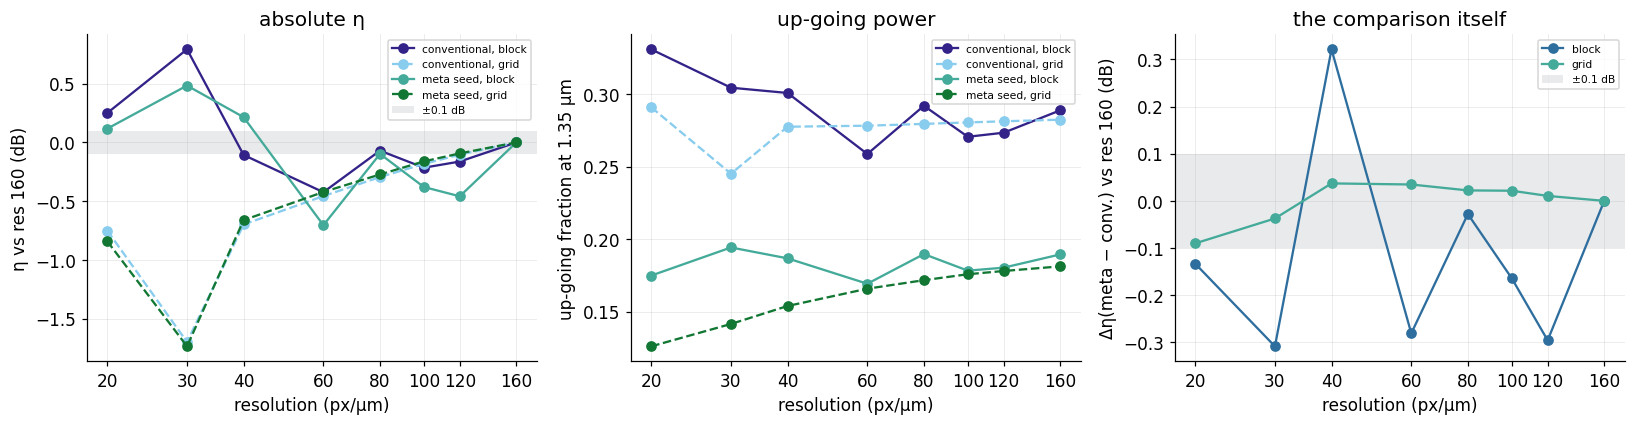

 res | eta vs res 160 (dB): conv block / conv grid / meta block / meta grid | meta-conv diff vs res 160 (dB): block / grid
  20 |         +0.250         -0.751         +0.117         -0.841 |     -0.133   -0.090
  30 |         +0.792         -1.697         +0.483         -1.735 |     -0.308   -0.037
  40 |         -0.107         -0.698         +0.214         -0.661 |     +0.321   +0.037
  60 |         -0.424         -0.457         -0.704         -0.422 |     -0.281   +0.035
  80 |         -0.070         -0.295         -0.098         -0.273 |     -0.028   +0.022
 100 |         -0.215         -0.183         -0.379         -0.161 |     -0.164   +0.021
 120 |         -0.163         -0.104         -0.458         -0.094 |     -0.296   +0.011
 160 |         +0.000         +0.000         +0.000         +0.000 |     +0.000   +0.000


In [7]:
# Convergence of eta, the up-going fraction, and the meta-vs-conventional difference.
def db(a, b):
    return 10 * np.log10(a / b)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for (n, kind), c in zip(mesh, style.COLOR_CYCLE):
    m = mesh[(n, kind)]
    ref = m[RES_LIST[-1]]
    lab = f"{'conventional' if n == 1 else 'meta seed'}, {kind}"
    ls = "-" if kind == "block" else "--"
    axes[0].plot(RES_LIST, [db(m[r]["eta"], ref["eta"]) for r in RES_LIST], "o" + ls, color=c, label=lab)
    axes[1].plot(RES_LIST, [m[r]["up"] for r in RES_LIST], "o" + ls, color=c, label=lab)
for kind, c in (("block", style.COLOR_STEEL), ("grid", style.COLOR_CYCLE[2])):
    diff = [db(mesh[(3, kind)][r]["eta"], mesh[(1, kind)][r]["eta"]) for r in RES_LIST]
    axes[2].plot(RES_LIST, [x - diff[-1] for x in diff], "o-", color=c, label=kind)
axes[0].axhspan(-0.1, 0.1, color=style.COLOR_REFERENCE, alpha=0.15, lw=0, label="±0.1 dB")
axes[2].axhspan(-0.1, 0.1, color=style.COLOR_REFERENCE, alpha=0.15, lw=0, label="±0.1 dB")
axes[0].set(ylabel="η vs res 160 (dB)", title="absolute η")
axes[1].set(ylabel="up-going fraction at 1.35 µm", title="up-going power")
axes[2].set(ylabel="Δη(meta − conv.) vs res 160 (dB)", title="the comparison itself")
for ax in axes:
    ax.set(xscale="log", xlabel="resolution (px/µm)")
    ax.set_xticks(RES_LIST, [str(r) for r in RES_LIST])
    ax.minorticks_off()
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

print(f"{'res':>4} | {'eta vs res 160 (dB): conv block / conv grid / meta block / meta grid':^62} | meta-conv diff vs res 160 (dB): block / grid")
for r in RES_LIST:
    e = [db(mesh[k][r]["eta"], mesh[k][RES_LIST[-1]]["eta"]) for k in ((1, "block"), (1, "grid"), (3, "block"), (3, "grid"))]
    dd = [db(mesh[(3, k)][r]["eta"], mesh[(1, k)][r]["eta"]) - db(mesh[(3, k)][160]["eta"], mesh[(1, k)][160]["eta"])
          for k in ("block", "grid")]
    print(f"{r:>4} | {e[0]:+14.3f} {e[1]:+14.3f} {e[2]:+14.3f} {e[3]:+14.3f} | {dd[0]:+10.3f} {dd[1]:+8.3f}")

**Reading the convergence.**

- **The `MaterialGrid` (fill-fraction) representation converges smoothly and
  monotonically**, with a first-order error: about −0.7 dB at res 40, −0.46 dB at res 60,
  −0.3 dB at res 80 relative to res 160, the same for both designs.
- **The `Block` representation does not converge monotonically.** It scatters by a few
  tenths of a dB from one resolution to the next, even above res 100. Meep's subpixel
  averaging builds an anisotropic ε tensor from the local interface normal; at the many
  groove *corners* that normal is ill-defined, and the resulting error depends on where
  each corner falls relative to the grid, which changes erratically with resolution. For
  physical TE the E field is parallel to every interface, so the arithmetic mean of ε
  (exactly what the fill-fraction grid uses) is the correct average everywhere,
  corners included. For this geometry the grid is therefore the more reliable
  representation, and it is the one used to optimize **and** to evaluate; `Block` stays
  as an independent cross-check.
- **The comparison itself converges much faster than either absolute value.** Both
  designs carry nearly the same systematic error at a given resolution, so the
  meta-minus-conventional difference stays within ~0.05 dB of its res-160 value from
  res 40 up (third panel). That difference is the quantity this study is about.

**Optimization resolution.** The coarsest resolution at which (a) the meta-vs-conventional
difference on the grid stays within 0.1 dB of res 160 at that and every finer
resolution, and (b) the 100 nm minimum feature spans at least 6 cells (res ≥ 60).
Final designs are re-evaluated at res 160.

In [8]:
# The optimization resolution from the criterion above.
def diff_db(r, kind="grid"):
    return db(mesh[(3, kind)][r]["eta"], mesh[(1, kind)][r]["eta"]) - db(mesh[(3, kind)][160]["eta"], mesh[(1, kind)][160]["eta"])


ok = [abs(diff_db(r)) <= 0.1 and r >= 60 for r in RES_LIST]
RES_OPT = next(r for i, r in enumerate(RES_LIST) if all(ok[i:]))
print(f"optimization resolution: res {RES_OPT} ({1000 / RES_OPT:.1f} nm cells, {100 * RES_OPT / 1000:.0f} cells across 100 nm); "
      f"grid bias there {db(mesh[(1, 'grid')][RES_OPT]['eta'], mesh[(1, 'grid')][160]['eta']):+.2f} dB (conventional), "
      f"{db(mesh[(3, 'grid')][RES_OPT]['eta'], mesh[(3, 'grid')][160]['eta']):+.2f} dB (meta); "
      f"one broadband forward run {mesh[(1, 'grid')][RES_OPT]['wall_s']:.0f} s")
RES_CANDIDATE = RES_OPT

optimization resolution: res 60 (16.7 nm cells, 6 cells across 100 nm); grid bias there -0.46 dB (conventional), -0.42 dB (meta); one broadband forward run 119 s


In [9]:
# Up-going power from the DFT near field vs Meep's flux monitor (same line), vs resolution.
def flux_check(res):
    r = sg.run_forward({**REF, "resolution": res})
    i0 = int(np.argmin(np.abs(r["wl"] - 1.35)))
    dx = r["x_up"][1] - r["x_up"][0]
    p_dft = -np.real(np.sum(-r["ez_up"][i0] * np.conj(r["hx_up"][i0]))) * dx / r["p_in"][i0]
    return float(p_dft), float(r["up"][i0])


fc = sg.cached(CACHE / "flux_check.pkl", lambda: {res: flux_check(res) for res in (20, 40, 80)})
for res, (a, b) in fc.items():
    print(f"res {res}: up from DFT fields {a:.4f}, flux monitor {b:.4f}, ratio {a / b:.4f}")

res 20: up from DFT fields 0.3224, flux monitor 0.3310, ratio 0.9742
res 40: up from DFT fields 0.2990, flux monitor 0.3009, ratio 0.9937
res 80: up from DFT fields 0.2916, flux monitor 0.2920, ratio 0.9985


## 6. Design period from the measured Bloch index

The design period follows the first-order phase-matching condition
P = λ / (n_B − n_ox sin θ). The Bloch index n_B of the conventional reference grating is
measured from the phase slope of its emitted field on the near-field line
(k_x = k₀(n_B − λ/P_ref)) at the finest resolution. Both the conventional and the meta
grating then use this one fixed period.

In [10]:
# n_B from the emitted field's phase slope, and the design period for a 10 deg fiber.
r160 = sg.cached(CACHE / "ref_res160_field.pkl", lambda: sg.run_forward({**REF, "resolution": 160}))
i0 = int(np.argmin(np.abs(r160["wl"] - 1.35)))
x = r160["x_up"]
sel = (x > 1.0) & (x < r160["dom"]["x_g1"] - 1.0)
kx = np.polyfit(x[sel], np.unwrap(np.angle(r160["ez_up"][i0][sel])), 1)[0]
N_B = kx / K0 + 1.35 / REF["period_um"]
theta_ref = math.degrees(math.asin(kx / K0 / 1.44))
P_DESIGN = round(1.35 / (N_B - 1.44 * math.sin(math.radians(10.0))), 3)
print(f"reference grating: emission {theta_ref:+.2f} deg, Bloch index n_B = {N_B:.4f}")
print(f"design period for a +10 deg fiber: P = {P_DESIGN:.3f} um "
      f"(n_B lies between the etched {N_TMM_ETCHED:.3f} and unetched {N_TMM:.3f} slab indices)")
assert N_TMM_ETCHED < N_B < N_TMM
UNI_SEED = {"period_um": P_DESIGN, "n_atoms": 1, "widths_um": [P_DESIGN / 2, P_DESIGN / 2], "etch_um": 0.20}
s = P_DESIGN / META["period_um"]
META_SEED = {**META, "period_um": P_DESIGN, "widths_um": [w * s for w in META["widths_um"]]}
print("seeds at the design period:", UNI_SEED["widths_um"], [round(w, 4) for w in META_SEED["widths_um"]])

reference grating: emission +8.32 deg, Bloch index n_B = 1.7084
design period for a +10 deg fiber: P = 0.926 um (n_B lies between the etched 1.613 and unetched 1.779 slab indices)
seeds at the design period: [np.float64(0.463), np.float64(0.463)] [np.float64(0.2572), np.float64(0.1235), np.float64(0.1543), np.float64(0.1029), np.float64(0.1338), np.float64(0.1543)]


## 7. BOX thickness: a standing wave in the BOX

About half of the light the grating scatters goes **down**. It crosses the BOX at the
emission angle θ, reflects at the Si substrate, and comes back up to interfere with the
light that went up directly. The two add in phase when the extra round-trip phase,
2 n_ox t cos θ · 2π/λ plus the reflection phases, is a multiple of 2π. As the BOX
thickness t grows, the up-going power therefore oscillates with a period

Λ_BOX = λ / (2 n_ox cos θ) ≈ 1.35 / (2 · 1.44 · cos 10°) ≈ 0.48 µm,

i.e. one more half-wavelength (λ/n_ox ≈ 0.94 µm) standing in the BOX per period. The
substrate reflection is set by the oxide/Si index step, not by t, so the oscillation does
not die out for a thick BOX; t only decides whether the reflection helps or hurts.

The conventional seed at the design period is swept over t = 1.0–5.0 µm in 0.05 µm steps
at res 40 (10 samples per period). A cosine fit gives the measured period, to compare
with Λ_BOX. The peak nearest a standard commercial BOX thickness is then refined in
0.02 µm steps at the optimization resolution and fixed for everything that follows.

emission angle in the BOX 10.0 deg -> predicted period lambda/(2 n cos theta) = 0.476 um
fitted period of the up-going fraction: 0.473 um; up-going fraction 0.25-0.64
eta peaks: 1.25 um (0.370), 1.70 um (0.348), 2.15 um (0.359), 2.65 um (0.355), 3.15 um (0.366), 3.60 um (0.361), 4.10 um (0.363), 4.55 um (0.364)
peak closest to a standard BOX: 4.55 um (+0.05 um from Applied Nanotools SiN MPW, 4.5 um)


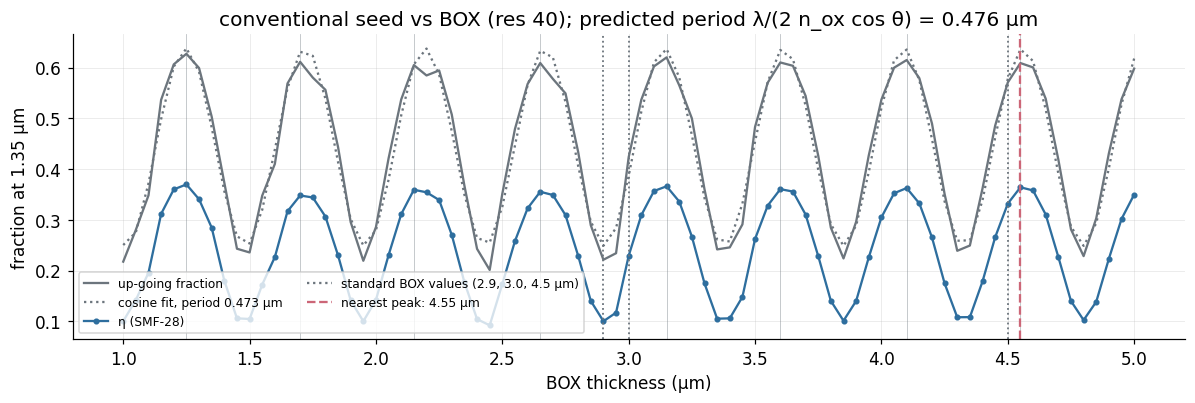

In [11]:
# Coarse sweep (res 40, 0.05 um steps) and a cosine fit of the up-going fraction.
from scipy.optimize import curve_fit

THETA_BOX = math.asin((N_B - 1.35 / P_DESIGN) / 1.44)          # emission angle in oxide (= in the BOX)
LAMBDA_BOX = 1.35 / (2 * 1.44 * math.cos(THETA_BOX))
BOXES = np.round(np.arange(1.0, 5.0001, 0.05), 3)
box_runs = {float(b): sg.cached(CACHE / "box_res40" / f"box_{b:.2f}.pkl",
                                lambda: summarize(sg.run_forward({**UNI_SEED, "resolution": 40, "box_um": float(b)})))
            for b in BOXES}
t = np.array(list(box_runs))
up = np.array([box_runs[b]["up"] for b in t])
eta = np.array([box_runs[b]["eta"] for b in t])
cosfit = lambda t, a, b, L, ph: a + b * np.cos(2 * np.pi * t / L + ph)
popt, _ = curve_fit(cosfit, t, up, p0=[up.mean(), (up.max() - up.min()) / 2, LAMBDA_BOX, 0.0])
print(f"emission angle in the BOX {math.degrees(THETA_BOX):.1f} deg -> predicted period lambda/(2 n cos theta) = {LAMBDA_BOX:.3f} um")
print(f"fitted period of the up-going fraction: {abs(popt[2]):.3f} um; up-going fraction {popt[0] - abs(popt[1]):.2f}-{popt[0] + abs(popt[1]):.2f}")

pk = [i for i in range(1, len(t) - 1) if eta[i] >= eta[i - 1] and eta[i] >= eta[i + 1]]
print("eta peaks:", ", ".join(f"{t[i]:.2f} um ({eta[i]:.3f})" for i in pk))
# Commonly used bottom-oxide thicknesses of SiN platforms (um): imec's 200 mm pilot line (2.5 um thermal +
# 0.4 um HDP), standard thermal-oxide wafers, Applied Nanotools' 400 nm SiN MPW (also Fraser et al. 2024).
STANDARD_BOX = {"imec pilot line": 2.9, "thermal-oxide wafer": 3.0, "Applied Nanotools SiN MPW": 4.5}
cands = sorted(((abs(t[i] - v), t[i], k) for i in pk for k, v in STANDARD_BOX.items()), key=lambda c: (round(c[0], 2), c[1]))
_, BOX_COARSE, BOX_REF = cands[0]
BOX_COARSE, BOX_STANDARD = float(BOX_COARSE), STANDARD_BOX[BOX_REF]
print(f"peak closest to a standard BOX: {BOX_COARSE:.2f} um ({BOX_COARSE - BOX_STANDARD:+.2f} um from {BOX_REF}, {BOX_STANDARD} um)")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, up, "-", color=style.COLOR_REFERENCE, label="up-going fraction")
ax.plot(t, cosfit(t, *popt), ":", color=style.COLOR_REFERENCE, label=f"cosine fit, period {abs(popt[2]):.3f} µm")
ax.plot(t, eta, "o-", ms=3, color=style.COLOR_STEEL, label="η (SMF-28)")
for i in pk:
    ax.axvline(t[i], color=style.COLOR_REFERENCE, lw=0.5, alpha=0.5)
for k, v in STANDARD_BOX.items():
    ax.axvline(v, color=style.COLOR_REFERENCE, lw=1.2, ls=":")
ax.plot([], [], ls=":", color=style.COLOR_REFERENCE, label="standard BOX values (2.9, 3.0, 4.5 µm)")
ax.axvline(BOX_COARSE, color=style.COLOR_ROSE, lw=1.5, ls="--", label=f"nearest peak: {BOX_COARSE:.2f} µm")
ax.set(xlabel="BOX thickness (µm)", ylabel="fraction at 1.35 µm",
       title=f"conventional seed vs BOX (res 40); predicted period λ/(2 n_ox cos θ) = {LAMBDA_BOX:.3f} µm")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**Which peak.** The peaks are nearly equally high, as expected from a thickness-independent
substrate reflection, so the choice should follow what is actually fabricated rather
than squeeze out efficiency with a custom stack. Commonly used SiN platforms put the core
on 2.9 µm (imec's 200 mm pilot line: 2.5 µm thermal oxide + 0.4 µm HDP oxide), on 3 µm
(standard thermal-oxide wafers), or on 4.5 µm (Applied Nanotools' 400 nm SiN MPW, also
Fraser et al. 2024). The chosen BOX is the interference peak closest to one of these
standard values (the thinner one when two are equally close), refined at the
optimization resolution below. A thinner BOX is also slightly better optically: the
reflected beam is shifted sideways by 2 t tan θ relative to the direct beam (≈ 1.0 µm at
3 µm, ≈ 1.6 µm at 4.5 µm), so it overlaps the direct beam better.

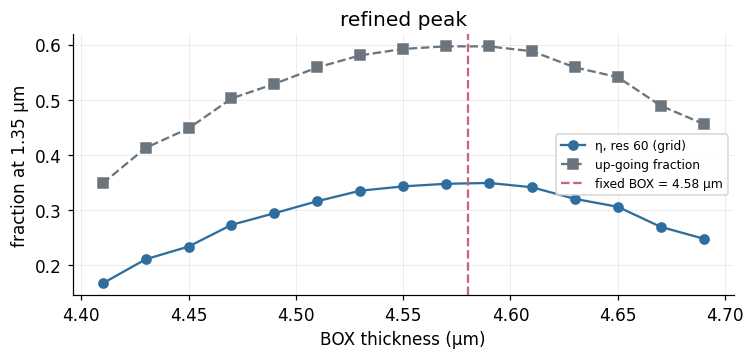

BOX fixed at 4.58 um (eta 0.348 for the conventional seed); a +/-0.05 um BOX error costs -0.38 / -0.18 dB


In [12]:
# Fine sweep around the chosen peak at the optimization resolution; fix the BOX there.
FINE = np.round(np.arange(BOX_COARSE - 0.14, BOX_COARSE + 0.1401, 0.02), 3)
box_fine = {float(b): sg.cached(CACHE / f"box_res{RES_OPT}" / f"box_{b:.2f}.pkl",
                                lambda: summarize(sg.run_forward({**UNI_SEED, "resolution": RES_OPT, "box_um": float(b)}, "grid")))
            for b in FINE}
tf = np.array(list(box_fine))
ef = np.array([box_fine[b]["eta"] for b in tf])
k = int(np.argmax(ef))
c = np.polyfit(tf[max(k - 2, 0):k + 3], ef[max(k - 2, 0):k + 3], 2)
BOX_UM = round(float(-c[1] / (2 * c[0])), 2)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(tf, ef, "o-", color=style.COLOR_STEEL, label=f"η, res {RES_OPT} (grid)")
ax.plot(tf, [box_fine[b]["up"] for b in tf], "s--", color=style.COLOR_REFERENCE, label="up-going fraction")
ax.axvline(BOX_UM, color=style.COLOR_ROSE, lw=1.5, ls="--", label=f"fixed BOX = {BOX_UM:.2f} µm")
ax.set(xlabel="BOX thickness (µm)", ylabel="fraction at 1.35 µm", title="refined peak")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"BOX fixed at {BOX_UM:.2f} um (eta {np.interp(BOX_UM, tf, ef):.3f} for the conventional seed); "
      f"a +/-0.05 um BOX error costs {10 * np.log10(np.interp(BOX_UM + 0.05, tf, ef) / ef.max()):.2f} / "
      f"{10 * np.log10(np.interp(BOX_UM - 0.05, tf, ef) / ef.max()):.2f} dB")

## 8. Is η a smooth function of the widths?

Adam follows the gradient, so η must change smoothly when a width moves by a fraction
of a cell. With Meep's subpixel averaging (`Block`) and with the fill-fraction
`MaterialGrid` it should; a staircased geometry would instead give flat steps with
jumps at every cell boundary. The first SiN width of the meta seed is moved ±10 nm in
1 nm steps (the last groove absorbs the change, so the period stays fixed), with the
fiber held at the seed's best position, at the candidate resolutions.

 grid res  40: max |second difference| / mean |first difference| = 0.112
 grid res  60: max |second difference| / mean |first difference| = 0.099
block res  60: max |second difference| / mean |first difference| = 1.745
 grid res  80: max |second difference| / mean |first difference| = 0.049


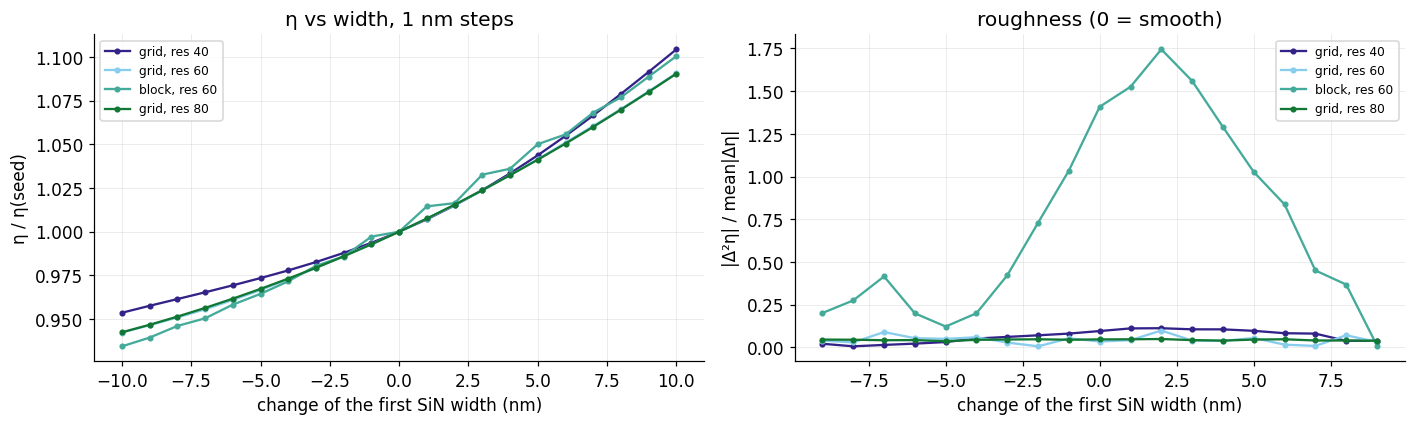

In [13]:
SMOOTH_RES = [40, 60, 80]
DW = np.arange(-0.010, 0.0101, 0.001)


def smooth_scan(res, kind):
    base = sg.run_forward({**META_SEED, "resolution": res}, kind)
    x0, _ = sg.best_x0(base)
    out = []
    for dw in DW:
        w = list(META_SEED["widths_um"])
        w[0] += dw
        out.append(summarize(sg.run_forward({**META_SEED, "widths_um": w, "resolution": res}, kind), x0=x0)["eta"])
    return np.array(out)


smooth = {(res, kind): sg.cached(CACHE / f"smooth_{kind}_res{res}.pkl", lambda: smooth_scan(res, kind))
          for res in SMOOTH_RES for kind in ("grid", "block") if kind == "grid" or res == 60}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (res, kind), c in zip(smooth, style.COLOR_CYCLE):
    e = smooth[(res, kind)]
    axes[0].plot(1e3 * DW, e / e[len(e) // 2], "o-", ms=3, color=c, label=f"{kind}, res {res}")
    d2 = np.abs(np.diff(e, 2)) / np.abs(np.diff(e)).mean()
    axes[1].plot(1e3 * DW[1:-1], d2, "o-", ms=3, color=c, label=f"{kind}, res {res}")
    print(f"{kind:>5} res {res:>3}: max |second difference| / mean |first difference| = {d2.max():.3f}")
axes[0].set(xlabel="change of the first SiN width (nm)", ylabel="η / η(seed)", title="η vs width, 1 nm steps")
axes[1].set(xlabel="change of the first SiN width (nm)", ylabel="|Δ²η| / mean|Δη|", title="roughness (0 = smooth)")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 9. Adjoint gradient vs finite differences

The optimizer's gradient comes from Meep's adjoint solver (∂η/∂ρ on the MaterialGrid)
chained through the fill-fraction parametrization (∂ρ/∂θ, autograd). It is compared
with central finite differences (±2 nm, ±2 nm etch) for every parameter of both
designs at the optimization resolution and at res 80. Because the period is fixed and the slack goes into
the last groove, that groove's own width parameter has no effect: its derivative is
exactly zero in both methods. The free parameters are therefore 2 for the conventional
grating (tooth width, etch) and 6 for the meta grating (5 widths, etch).

In [14]:
def grad_check(design, res, h=0.002):
    p = sg.resolve({**design, "resolution": res})
    base = sg.run_forward(p, "grid")
    i0 = int(np.argmin(np.abs(base["wl"] - 1.35)))
    ap = sg.AdjointProblem(p, base["p_in"][i0])
    ap.x0, _ = sg.best_x0(base)
    th = sg.theta_of(p)
    t = time.perf_counter()
    f, g = ap.value_and_grad(th)
    t_iter = time.perf_counter() - t
    fd = []
    for k in range(len(th)):
        tp, tm = th.copy(), th.copy()
        tp[k] += h
        tm[k] -= h
        fd.append((ap.value(tp) - ap.value(tm)) / (2 * h))
    return {"eta": f, "adjoint": g, "fd": np.array(fd), "t_iter_s": t_iter}


GRAD_RES = sorted({RES_OPT, 80})
gc = {(n, res): sg.cached(CACHE / f"grad_{n}atom_res{res}.pkl", lambda: grad_check(dsn, res))
      for res in GRAD_RES for n, dsn in ((1, UNI_SEED), (3, META_SEED))}
for (n, res), g in gc.items():
    print(f"{'conventional' if n == 1 else 'meta seed'} at res {res}: eta {g['eta']:.4f}, "
          f"one forward+adjoint {g['t_iter_s']:.0f} s")
    names = [f"w{i + 1}" for i in range(len(g['fd']) - 1)] + ["etch"]
    for nm, a, f in zip(names, g["adjoint"], g["fd"]):
        rel = abs(a - f) / max(abs(f), 1e-12)
        print(f"   {nm:>5}: adjoint {a:+.5f}  finite diff {f:+.5f}  rel. error {rel:.2%}")
    nz = np.abs(g["fd"]) > 1e-3 * np.abs(g["fd"]).max()
    assert np.all(np.abs(g["adjoint"][nz] - g["fd"][nz]) <= 0.05 * np.abs(g["fd"][nz])), "adjoint gradient off by >5%"

conventional at res 60: eta 0.1269, one forward+adjoint 235 s
      w1: adjoint +0.31713  finite diff +0.31406  rel. error 0.98%
      w2: adjoint +0.00000  finite diff +0.00000  rel. error 0.00%
    etch: adjoint -1.05766  finite diff -1.05534  rel. error 0.22%
meta seed at res 60: eta 0.0069, one forward+adjoint 273 s
      w1: adjoint +0.04852  finite diff +0.05017  rel. error 3.30%
      w2: adjoint -0.17850  finite diff -0.17749  rel. error 0.57%
      w3: adjoint -0.07921  finite diff -0.07860  rel. error 0.77%
      w4: adjoint +0.05305  finite diff +0.05361  rel. error 1.04%
      w5: adjoint -0.19086  finite diff -0.19030  rel. error 0.29%
      w6: adjoint +0.00000  finite diff +0.00000  rel. error 0.00%
    etch: adjoint -0.02170  finite diff -0.02171  rel. error 0.05%
conventional at res 80: eta 0.1299, one forward+adjoint 653 s
      w1: adjoint +0.29567  finite diff +0.29741  rel. error 0.58%
      w2: adjoint -0.00000  finite diff +0.00000  rel. error 0.00%
    etch: adj

## 10. Literature benchmark: single-etch SiN coupler (Korček et al., 2023)

A published, fabricated single-etch SiN coupler checks that this 2D model reproduces
known numbers on a different stack: 400 nm SiN **fully etched**, **air** top cladding,
6 µm BOX, 1.55 µm, period 860 nm, duty cycle 70 %, SMF-28 with MFD 10.4 µm. The
paper reports a simulated −3.6 dB (measured −3.9 dB) and 72 % directionality for its
uniform design (Lumerical FDTD, 10 nm mesh). The fiber angle is not given, so it is
scanned here together with the fiber position. A 2D model has no lateral mode
mismatch, so it is expected to sit somewhat above a 3D or measured value.

In [15]:
KORCEK = {"wl0_um": 1.55, "wl_min_um": 1.50, "wl_max_um": 1.60, "n_top": 1.0, "box_um": 6.0, "etch_um": 0.40,
          "period_um": 0.86, "n_atoms": 1, "widths_um": [0.602, 0.258], "n_periods": 25, "mfd_um": 10.4}
kr = {res: sg.cached(CACHE / f"korcek_res{res}.pkl", lambda: sg.run_forward({**KORCEK, "resolution": res}))
      for res in (60, 100)}
for res, r in kr.items():
    i0 = int(np.argmin(np.abs(r["wl"] - 1.55)))
    best = max(((a, *sg.best_x0(r, i0, angle_deg=a)) for a in np.arange(-20, 20.1, 0.5)), key=lambda t: t[2])
    direc = r["up"][i0] / (r["up"][i0] + r["down"][i0])
    print(f"res {res}: eta {best[2]:.3f} ({10 * np.log10(best[2]):.2f} dB) at fiber angle {best[0]:+.1f} deg (air); "
          f"directionality {direc:.0%}; R {r['R'][i0]:.3f}, T {r['T'][i0]:.3f}")
print("paper (Korcek 2023, uniform, 1.55 um): -3.6 dB simulated, -3.9 dB measured, directionality 72%")

res 60: eta 0.430 (-3.67 dB) at fiber angle -16.0 deg (air); directionality 73%; R 0.088, T 0.071


res 100: eta 0.430 (-3.66 dB) at fiber angle -16.0 deg (air); directionality 73%; R 0.087, T 0.073
paper (Korcek 2023, uniform, 1.55 um): -3.6 dB simulated, -3.9 dB measured, directionality 72%


## 11. Summary

The cell below collects the numbers that set up Steps 2 and 3, and saves them to
`meta/data/step1/summary.json`.

> **STOP -- review the convergence, smoothness and gradient results. Steps 2 and 3 use
> the optimization resolution, design period and BOX thickness saved here.**

In [16]:
summary = {
    "n_eff_tmm": N_TMM, "n_eff_meep": {r: n for r, n, _ in rows},
    "straight_guide": wg, "domain_max_eta_change": DOMAIN_SPREAD,
    "mesh": {f"{n}atom_{kind}": {r: m[r] for r in RES_LIST} for (n, kind), m in mesh.items()},
    "res_opt": RES_OPT, "n_bloch_ref": N_B, "period_design_um": P_DESIGN,
    "box_sweep_res40": box_runs, "box_fine": box_fine, "box_um": BOX_UM,
    "box_period_fit_um": abs(float(popt[2])), "box_period_predicted_um": LAMBDA_BOX,
    "grad_check": {f"{n}atom_res{res}": {"adjoint": g["adjoint"].tolist(), "fd": g["fd"].tolist(), "t_iter_s": g["t_iter_s"]}
                   for (n, res), g in gc.items()},
}
(CACHE / "summary.json").write_text(json.dumps(summary, indent=1, default=float))
print(json.dumps({k: summary[k] for k in ("res_opt", "period_design_um", "n_bloch_ref", "box_um", "box_period_fit_um",
                                          "box_period_predicted_um", "domain_max_eta_change")},
                 indent=1, default=float))

{
 "res_opt": 60,
 "period_design_um": 0.926,
 "n_bloch_ref": 1.7084421455327774,
 "box_um": 4.58,
 "box_period_fit_um": 0.4734996608446235,
 "box_period_predicted_um": 0.47601116832329227,
 "domain_max_eta_change": 0.00026913022444863266
}
